# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [183]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [184]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, average_precision_score

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

        # ваше решение здесь
        pass### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [185]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        X = np.column_stack((np.ones(X.shape[0]), X))
        self.w = np.zeros(X.shape[1]) if self.w0 is None else self.w0.copy()

        for i in range (1, self.max_iter + 1):
            self.loss_history.append(self.calc_loss(X, y))
            if self.gd_type == 'full': grad = self.calc_gradient(X, y)
            elif self.gd_type == 'stochastic': grad = self.calc_grad_on_batch(X, y, rng)
            else: raise Exception('Invalid gd_type')
            old = self.w.copy()
            self.w = self.w - self.eta * grad
            if np.linalg.norm(self.w - old) < self.tolerance: break

        return self

    def sigmoid(self, z):
        return np.where(
            z >= 0,
            1 / (1 + np.exp(-z)),
            np.exp(z) / (1 + np.exp(z))
        )


    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        X = np.column_stack((np.ones(X.shape[0]), X))
        p = self.sigmoid(X @ self.w)
        return np.column_stack((1 - p, p))

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        p = self.predict_proba(X)[:, 1]
        return np.where(p >= threshold, 1, 0)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        p = self.sigmoid(X @ self.w)
        return X.T @ (p - y) / X.shape[0]

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        p = self.sigmoid(X @ self.w)
        p = np.clip(p, 1e-15, 1 - 1e-15)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def calc_grad_on_batch(self, X, y, rng):
        ind = rng.choice(X.shape[0], size=min(self.batch_size, X.shape[0]), replace=False)
        batch_X = X[ind]
        batch_y = y[ind]
        return self.calc_gradient(batch_X, batch_y)

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [186]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 2.55e-10


Теперь проверим работу класса на синтетических данных.

In [187]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

,Full GD,Stochastic GD
Количество итераций,1000,1000


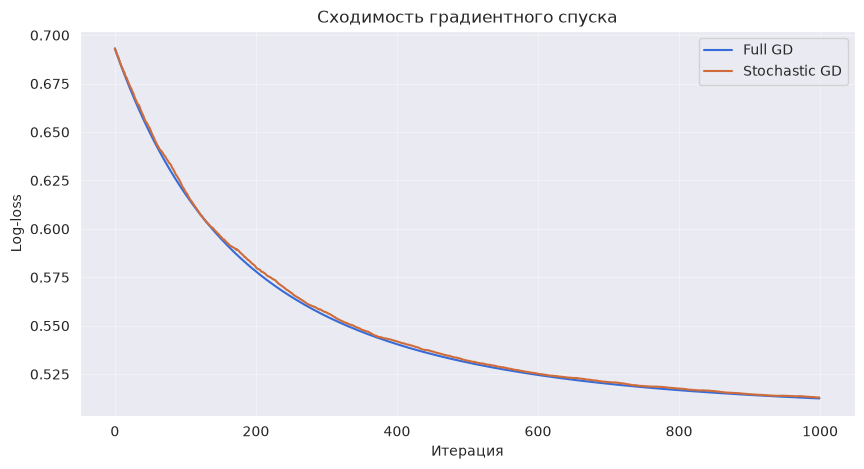

In [188]:
model = LogReg(gd_type='full')
model_sgd = LogReg(gd_type='stochastic')
model.fit(X_train, y_train)
model_sgd.fit(X_train, y_train)

lh = model.loss_history
lh_sgd = model_sgd.loss_history

display(pd.DataFrame({
    'Full GD': [len(lh)],
    'Stochastic GD': [len(lh_sgd)]
}, index=['Количество итераций']))

plt.figure(figsize=(10, 5))

plt.plot(lh, label='Full GD')
plt.plot(lh_sgd, label='Stochastic GD')

plt.xlabel('Итерация')
plt.ylabel('Log-loss')
plt.title('Сходимость градиентного спуска')
plt.legend()
plt.grid(True)
plt.show()

#### Выводы

Каждая модель остановилась по `max_iter`.

SGD трудно остановиться по `tolerance` из-за шума, который создаётся из-за случайных батчей размеров `batch_size`, т. е. при достаточно низком `tolerance` размер шума будет больше критерия останова.

Графики функции потерь почти не отличаются, ОДНАКО SGD более шумный и "дёрганный", и он всегда немного выше Full GD.

Очевидно, Full GD просматривает ВСЕ объекты за итерацию, а SGD только `batch_size` объектов.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

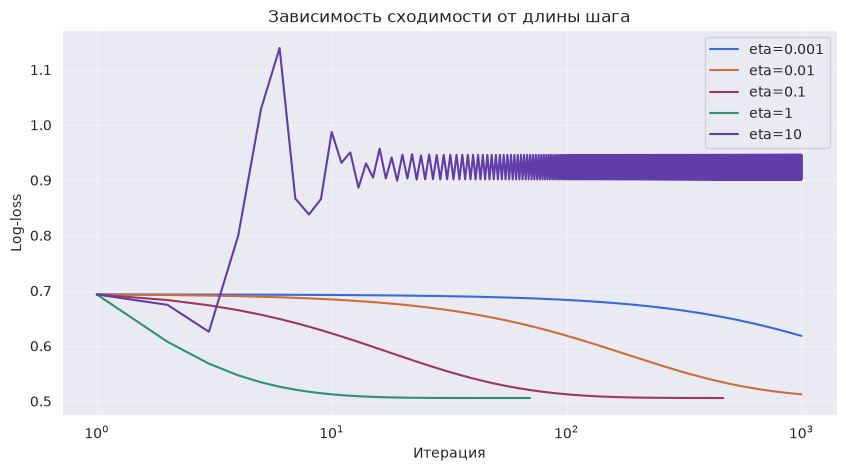

,eta,final Log-loss,Кол-во итераций
0,0.001,0.618141,1000
1,0.010,0.512451,1000
2,0.100,0.505762,465
3,1.000,0.505757,70
4,10.000,0.945807,1000


In [189]:
etas = [1e-3, 1e-2, 1e-1, 1, 10]
results = []

plt.figure(figsize=(10, 5))

for eta in etas:
    model_tmp = LogReg(gd_type='full', eta=eta)
    model_tmp.fit(X_train, y_train)

    lh = model_tmp.loss_history

    results.append({
        'eta': eta,
        'final Log-loss': lh[-1],
        'Кол-во итераций': len(lh)
    })

    plt.plot(range(1, len(lh) + 1), lh, label=f'eta={eta}')

plt.xscale('log')
plt.xlabel('Итерация')
plt.ylabel('Log-loss')
plt.title('Зависимость сходимости от длины шага')
plt.legend()
plt.grid(True)
plt.show()

display(pd.DataFrame(results))

#### Выводы

При малом `eta` сходится дольше, но качественее из-за более мелких шагов, а при большом `eta`, наоборот, сходится быстрее (или вообще не сходится, если шаг чересчур большой), но уже не так качественно, потому что итоговая функция потерь может быть большом, как при малом.
Стоит заметить, что малое `eta` при небольшом кол-во итераций может показать себя хуже в плане финального Log-loss.

В нашем случае при дефолтном `max_iter` = 1000 плохими `eta` можно назвать все значения, при которых не сходится спуск (судя по графику), т. е. 0.001, 0.01 и 10. ОДНАКО, если увеличить кол-во итераций `max_iter` до определённого значения, то уже сойдутся все `eta`, кроме 10, потому что даже сейчас при нём Log-loss застревает близ 0.95.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [190]:
model_sk = LogisticRegression()
model_sk.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_sgd = model_sgd.predict(X_test)
y_pred_sk = model_sk.predict(X_test)

display(pd.DataFrame({
    'accuracy': [np.mean(y_pred == y_test), np.mean(y_pred_sgd == y_test), np.mean(y_pred_sk == y_test)],
    'ROC-AUC': [roc_auc_score(y_test, y_pred), roc_auc_score(y_test, y_pred_sgd), roc_auc_score(y_test, y_pred_sk)],
}, index=['Full GD', 'SGD', 'sklearn']))

display(pd.DataFrame({
    'Full GD': model.w,
    'sklearn': np.r_[model_sk.intercept_, model_sk.coef_.ravel()]
}, index=['intercept'] + [f'w{i}' for i in range(1, len(model.w))]))

,accuracy,ROC-AUC
Full GD,0.7820,0.782002
SGD,0.7825,0.782498
sklearn,0.7765,0.776497


,Full GD,sklearn
intercept,-0.002114,-0.021880
w1,0.006076,0.002741
w2,0.006963,0.009039
w3,-0.547170,-0.722690
w4,-0.144536,-0.262335
w5,0.012487,0.016588
w6,-0.006325,-0.011488
w7,0.000814,0.005587
w8,0.039084,0.057188
w9,-0.002425,-0.001239


#### Выводы

Метрики похожи и почти совпадают. Веса не совпадают, что объяснется тем, что у нашего GD по умолчанию `max_iter` = 1000, а у sklearn - `max_iter` = 100 (по заданию должны были использовать то, что по дефолту). Также помимо `max_iter` на веса влияют другие настройки sklearn логистической регрессии, например, L2-регуляризация по умолчанию.

Как говорилось ранее, модель sklearn не равной нашей задаче делает именно `max_iter` = 100 по умолчанию (у нас = 1000). Чтобы настроить под нашу задачу нужно `max_iter` сделать равным 1000. Также можно сказать и про `random_state` = 42, который у sklearn по умолчанию просто None.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [191]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [192]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [193]:
display(pd.DataFrame({
    'Пропуски': [df.isna().sum().sum()],
    'Дубликаты': [df.duplicated().sum()]
}, index=['df']))

display(pd.DataFrame({
    'train': [y_train[y_train==1].count() / len(y_train)],
    'test': [y_test[y_test==1].count() / len(y_test)]
}, index=['prevalence']))

model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

display(pd.DataFrame({
    'accuracy': [accuracy_score(y_test, np.zeros(len(y_test))), accuracy_score(y_test, y_pred)]
}, index=['const model', 'pipeline model']))

,Пропуски,Дубликаты
df,0,1177


,train,test
prevalence,0.196613,0.19641


,accuracy
const model,0.80359
pipeline model,0.82000


#### Выводы
В данной задаче важно отличать технические и реальные дубликаты (разные наблюдения, но признаки совпали), потому что реальные дубликаты сохраняют информацию о кол-ве того или иного объекта (в нашем случае это отражает редкость вина). В данной постановке задач дубликаты нельзя удалять, т. к. таким образом мы отражаем реальный мир - вина не всегда отличаются по своим показателям.

При разбиении параметр `stratify=y` нужен для того, чтобы доля более редких классов (судя по prevalence, в нашем случае это класс 1) не оказался вся (или большая её часть) в тестовой выборке или наоборот более частый класс не оказался полностью в тренировочной выборке.

`accuracy` плох для этой задачи из-за того, что доля класса 0 и 1 заметно отличаются, что видно по рассчитанному ранне `prevalence`, и, соответственно, правильные ответы по большой доле класса просто выдают больше точность для всей модели. Эту ситуацию мы и наблюдаем на рассчитанных `accuracy` для константной модели и для нормальной - `accuracy` почти не отличается, хотя константная модель предсказывает только класс 0.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

,actually IS class 1,actually IS class 0
class 1,TP = 98,FP = 66
class 0,FN = 285,TN = 1501


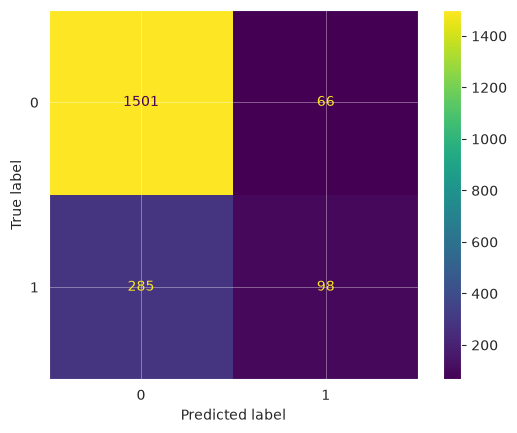

In [194]:
y_test_np = np.asarray(y_test)

(tp, fn, fp, tn) = (((y_pred==1) & (y_test_np==1)).sum(),
                    ((y_pred==0) & (y_test_np==1)).sum(),
                    ((y_pred==1) & (y_test_np==0)).sum(),
                    ((y_pred==0) & (y_test_np==0)).sum())

display(pd.DataFrame({
    'actually IS class 1': [f'TP = {tp}', f'FN = {fn}'],
    'actually IS class 0': [f'FP = {fp}', f'TN = {tn}'],
}, index=['class 1', 'class 0']))

metrics.ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()

#### Выводы
Наши матрицы полностью совпадают (немного отзеркалили, но судя по индексам класса, всё действительно одинаково).

В нашем сценарии `FP` это посредственные вина, которые мы назвали хорошими, а `FN` - хорошие вина, которые мы ошибочно записали в посредственные. Судя по матрице, чаще встречается `FN`, т. е. хорошие вина, ошибочно названные посредственными.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [195]:
def f_score(precision, recall, beta):
    return (1 + beta**2) * precision * recall / (beta**2 * precision + recall)

precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1_score = f_score(precision, recall, 1)
f05_score = f_score(precision, recall, 0.5)
f2_score = f_score(precision, recall, 2)

display(pd.DataFrame({
    'precision': [precision, metrics.precision_score(y_test, y_pred)],
    'recall': [recall, metrics.recall_score(y_test, y_pred)],
    'f1_score': [f1_score, metrics.fbeta_score(y_test, y_pred, beta=1)],
    'f05_score': [f05_score, metrics.fbeta_score(y_test, y_pred, beta=0.5)],
    'f2_score': [f2_score, metrics.fbeta_score(y_test, y_pred, beta=2)]
}, index=['Формульно', 'sklearn.metrics']))

,precision,recall,f1_score,f05_score,f2_score
Формульно,0.597561,0.255875,0.358318,0.471607,0.288915
sklearn.metrics,0.597561,0.255875,0.358318,0.471607,0.288915


#### Выводы
Результаты расчётов формульно и с помощью `sklearn.metrics` совпадают.

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}} \Rightarrow \frac{1}{F_{\beta}} = \frac{1}{1 + \beta^2} \frac{\beta^2 \cdot \text{Precision} + \text{Recall}}{\text{Precision} \cdot \text{Recall}} = \frac{1}{1 + \beta^2} (\frac{\beta^2}{\text{Recall}} + \frac{1}{\text{Precision}}) = \frac{\beta^2}{1 + \beta^2} \cdot \frac{1}{\text{Recall}} + \frac{1}{1 + \beta^2} \cdot \frac{1}{\text{Precision}}$$
Отсюда видно "вес" `recall` и `precision`. Таким образом, при `beta` = 0.5 веса для `recall` и `precision` - 0.2 и 0.8 соответственно, а при `beta` = 2 - 0.8 и 0.2 соответсвенно. Поэтому можно сделать вывод, что в $F_{0.5}$ больше ценится `precision`, а в $F_{2}$ - `recall`.

1. Если наши подписчики болезненно реагируют на посредственные вина, т. е. смотрят редкое вино и хотят быть уверены, что выбирают то самое дорогое изящное вино с виноградных плантаций Франции из деревни города N, то точность (`precision`) нам важнее - да, вкусовые способности наших дегустаторов иногда сбоят, но мы *уверены* в том, что вы выберете именно тот легендарный напиток. В таком случае для F-меры лучше взять `beta` < 1
2. Если наш сервис позицианирует себя как "самая широкая подборка хороших вин", т. е. хочет всем гордо заявить "мы обладатели самой большой коллекции редкого вина", то нам важна уже полнота (`recall`) - да, иногда мы называем маринад от сюрстрёминга величайшим вином, что сделало человечество, но зато мы *уверены* в том, что действительно собрали почти все лучшие вина этой планеты. В таком случае для F-меры лучше взять `beta` > 1
3. `beta` = 1 лучше, когда хотим сохранить баланс между тем и тем.

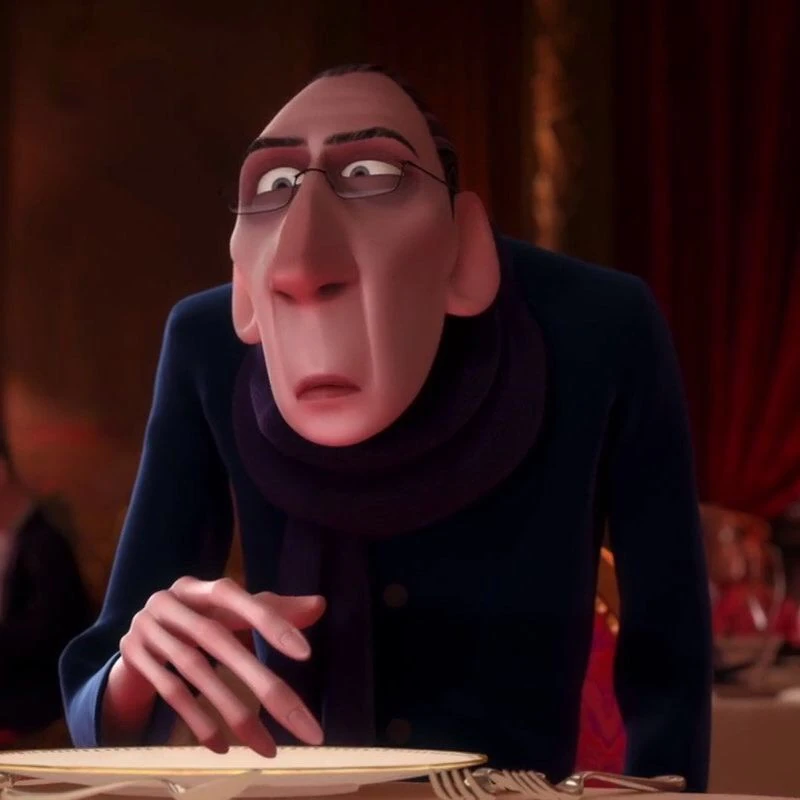

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

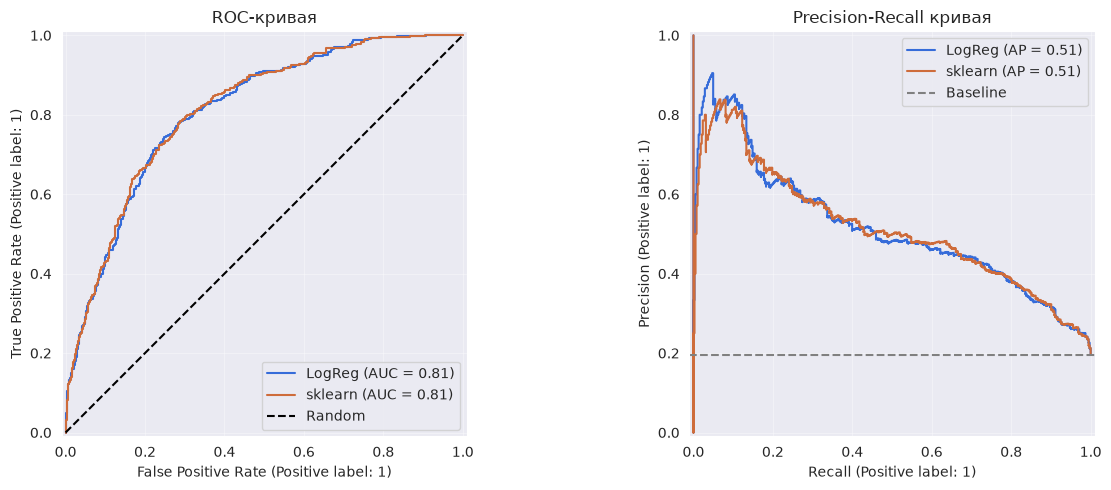

,ROC-AUC,PR-AUC
LogReg,0.811074,0.514390
sklearn,0.813537,0.512115


,ROC-AUC
p,0.811074
10p,0.811074
p^3,0.811074
log(p/(1-p)),0.811074
-p,0.188926


In [196]:
# LogReg
model = make_pipeline(StandardScaler(), LogReg(eta=0.1, max_iter=1000))
model.fit(X_train, y_train)
c1_score = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)

# sklearn
model_sk = make_pipeline(StandardScaler(), LogisticRegression())
model_sk.fit(X_train, y_train)
c1_score_sk = model_sk.predict_proba(X_test)[:, 1]
y_pred_sk = model_sk.predict(X_test)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# ROC
metrics.RocCurveDisplay.from_predictions(
    y_test, c1_score, name='LogReg', ax=ax[0]
)
metrics.RocCurveDisplay.from_predictions(
    y_test, c1_score_sk, name='sklearn', ax=ax[0]
)

ax[0].plot([0, 1], [0, 1], 'k--', label='Random')
ax[0].set_title('ROC-кривая')
ax[0].grid(True)
ax[0].legend()

# PR
metrics.PrecisionRecallDisplay.from_predictions(
    y_test, c1_score, name='LogReg', ax=ax[1]
)
metrics.PrecisionRecallDisplay.from_predictions(
    y_test, c1_score_sk, name='sklearn', ax=ax[1]
)

ax[1].axhline(y=np.mean(y_test), color='gray', linestyle='--', label='Baseline')
ax[1].set_title('Precision-Recall кривая')
ax[1].grid(True)
ax[1].legend()

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    'ROC-AUC': [roc_auc_score(y_test, c1_score), roc_auc_score(y_test, c1_score_sk)],
    'PR-AUC': [average_precision_score(y_test, c1_score), average_precision_score(y_test, c1_score_sk)]
}, index=['LogReg', 'sklearn']))

p = c1_score
scores = {
    'p': p,
    '10p': 10 * p,
    'p^3': p**3,
    'log(p/(1-p))': np.log(p / (1 - p)),
    '-p': -p
}

display(pd.DataFrame({
    'ROC-AUC': {
        name: metrics.roc_auc_score(y_test, score)
        for name, score in scores.items()
    }
}))

#### Выводы
ROC-AUC не меняется от преобразования оценок, если не меняется порядок объектов (так, например, при -p порядок изменился и соответственно оценка (хотя она просто равна 1 - ROC-AUC)).

С текущими метриками нельзя точно выявить какая модель лучше, потому что ранжирование по ROC-AUC и PR-AUC не совпадают.

PR-AUC случайной модели в этой задаче равен 0.2, потому что это доля класса 1 в выборке.

Если заменить вероятности на метки классов, то получится Balanced Accuracy.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

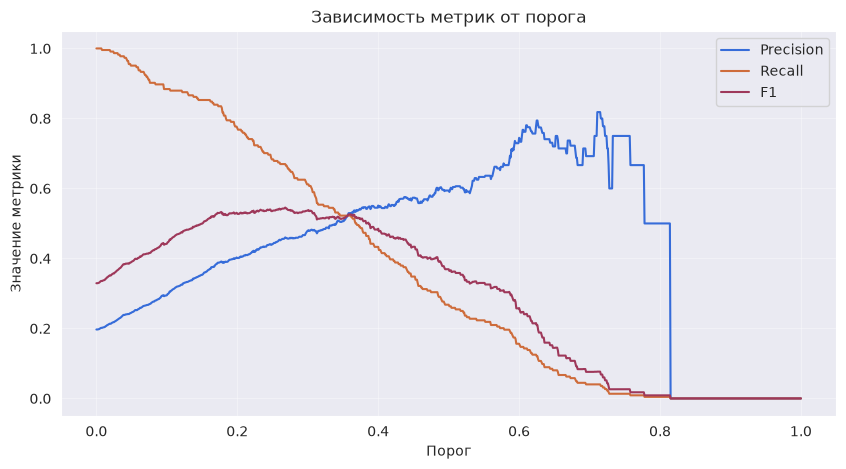

,Порог,Precision,Recall,F1
Максимальный F1,0.268,0.460123,0.669643,0.545455
Recall >= 0.7,0.243,0.438547,0.700893,0.539519


,Значение,Precision,Recall,F1
Порог,,,,
0.5,0.500,0.597561,0.255875,0.358318
t_F1,0.268,0.473180,0.644909,0.545856
t_R,0.243,0.436975,0.678851,0.531697


In [197]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=42
)

model_val = make_pipeline(StandardScaler(), LogisticRegression())
model_val.fit(X_tr, y_tr)

p_val = model_val.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0, 1, 1001)

precision = []
recall = []
f1 = []

for t in thresholds:
    y_pred_val = (p_val >= t).astype(int)

    precision.append(metrics.precision_score(y_val, y_pred_val, zero_division=0))
    recall.append(metrics.recall_score(y_val, y_pred_val))
    f1.append(metrics.f1_score(y_val, y_pred_val, zero_division=0))

precision = np.array(precision)
recall = np.array(recall)
f1 = np.array(f1)

plt.figure(figsize=(10, 5))

plt.plot(thresholds, precision, label='Precision')
plt.plot(thresholds, recall, label='Recall')
plt.plot(thresholds, f1, label='F1')

plt.xlabel('Порог')
plt.ylabel('Значение метрики')
plt.title('Зависимость метрик от порога')
plt.legend()
plt.grid(True)
plt.show()

t_f1 = thresholds[np.argmax(f1)]

mask = recall >= 0.7
t_r = thresholds[mask][np.argmax(precision[mask])]

display(pd.DataFrame({
    'Порог': [t_f1, t_r],
    'Precision': [precision[np.argmax(f1)], precision[mask][np.argmax(precision[mask])]],
    'Recall': [recall[np.argmax(f1)], recall[mask][np.argmax(precision[mask])]],
    'F1': [f1[np.argmax(f1)], f1[mask][np.argmax(precision[mask])]]
}, index=['Максимальный F1', 'Recall >= 0.7']))

model_final = make_pipeline(StandardScaler(), LogisticRegression())
model_final.fit(X_train, y_train)

p_test = model_final.predict_proba(X_test)[:, 1]

results = []

for name, t in {'0.5': 0.5, 't_F1': t_f1, 't_R': t_r}.items():
    y_pred = (p_test >= t).astype(int)

    results.append({
        'Порог': name,
        'Значение': t,
        'Precision': metrics.precision_score(y_test, y_pred, zero_division=0),
        'Recall': metrics.recall_score(y_test, y_pred),
        'F1': metrics.f1_score(y_test, y_pred, zero_division=0)
    })

display(pd.DataFrame(results).set_index('Порог'))

#### Выводы
Не выполнилось условие Recall >= 0.7, потому что порог подбираетя под распределение оценок наблюдений валидационной выборки, и соответственно уже на тестовой выборке Recall может стать как больше, так и меньше, чем на валидационной.

Для нашего сценария стоит выбрать порог 0.268, т. к. при нём самый большой F1, который сохраняет баланс между Precision и Recall - мы найдём больше по-настоящему хороших вин.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [198]:
def evaluate_model(model):
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]

    return {
        'Accuracy': metrics.accuracy_score(y_test, y_pred),
        'Precision': metrics.precision_score(y_test, y_pred),
        'Recall': metrics.recall_score(y_test, y_pred),
        'F1': metrics.f1_score(y_test, y_pred),
        'ROC-AUC': metrics.roc_auc_score(y_test, y_score),
        'PR-AUC': metrics.average_precision_score(y_test, y_score)
    }


model_none = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight=None)
)

model_balanced = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced')
)

model_none.fit(X_train, y_train)
model_balanced.fit(X_train, y_train)

results = pd.DataFrame({
    'None': evaluate_model(model_none),
    'Balanced': evaluate_model(model_balanced)
}).T

display(results)

counts = y_train.value_counts().sort_index()

weights = len(y_train) / (2 * counts)

display(pd.DataFrame({
    'Количество объектов': counts,
    'Вес класса': weights
}))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
None,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
Balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536


,Количество объектов,Вес класса
target,,
0,3653,0.622365
1,894,2.543065


#### Выводы
Сильно отличаются Precision, Recall и F1, что происходит из-за изменения весов ошибок в формуле потерь. Так штраф за ошибку на классе 1 выше и модель старается предсказывать этот класс чаще из-за чего больше больше ложноположительных предсказаний.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [199]:
from imblearn.pipeline import make_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {
    'RandomUnderSampler': RandomUnderSampler(random_state=42),
    'NearMiss': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(random_state=42),
    'SMOTE': SMOTE(random_state=42)
}

results_32 = results.copy()
class_counts = {}

for name, sampler in samplers.items():
    model = make_pipeline(
        StandardScaler(),
        sampler,
        LogisticRegression()
    )

    model.fit(X_train, y_train)

    results_32.loc[name] = evaluate_model(model)

    # Количество объектов после ресемплинга
    X_res, y_res = model[:-1].fit_resample(X_train, y_train)
    class_counts[name] = pd.Series(y_res).value_counts().sort_index()

display(results_32)
display(pd.DataFrame(class_counts).T)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
None,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
Balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
RandomUnderSampler,0.729744,0.401099,0.762402,0.525653,0.809354,0.500791
NearMiss,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
RandomOverSampler,0.726667,0.397260,0.757180,0.521114,0.811484,0.500225
SMOTE,0.729231,0.399166,0.749347,0.520871,0.812465,0.503985


target,0,1
RandomUnderSampler,894,894
NearMiss,894,894
RandomOverSampler,3653,3653
SMOTE,3653,3653


In [200]:
model_1 = make_pipeline(
    StandardScaler(),
    NearMiss(version=2),
    LogisticRegression()
)

model_2 = make_pipeline(
    NearMiss(version=2),
    StandardScaler(),
    LogisticRegression()
)

model_1.fit(X_train, y_train)
model_2.fit(X_train, y_train)

display(pd.DataFrame({
    'Scaler → NearMiss': evaluate_model(model_1),
    'NearMiss → Scaler': evaluate_model(model_2)
}).T)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Scaler → NearMiss,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
NearMiss → Scaler,0.681026,0.351183,0.736292,0.475548,0.755049,0.393364


#### Выводы
Нельзя pipeline из sklearn, потому что метод fit_resample() не поддерживается pipeline из sklearn. При вызове predict у такого пайплайна данные проскейлятся и отправятся классификатору (т. е. никакого ресемплинга).

Нельзя балансировать до разбиения из-за риска data-leakage (из-за используемой информации из будущей тестовой выборки) и оценки окажутся завышенными.

Лучшим по PR-AUC оказался SMOTE, а худшим NearMiss. SMOTE в отличие от NearMiss показал себя очень хорошо, потому что сохраняет информацию о наблюдениях выборки и интерполирует меньшенство, а NearMiss удаляет наблюдения, причём так, что остаётся большинство, и по итогу он показывает самые плохие метрики.

На RandomOverSampler и RandomUnderSampler не влияет порядок, т. к. они не ориентируются на масштаб показателей, однако этот порядок может повлиять на сам StandardScaler. Но порядок влияет на NearMiss и SMOTE, т. к. 1-ый использует расстояние между объектами, а 2-ой информацию о ближиайших соседях для генерации данных. Проверили на NearMiss и метрики сильно изменились.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

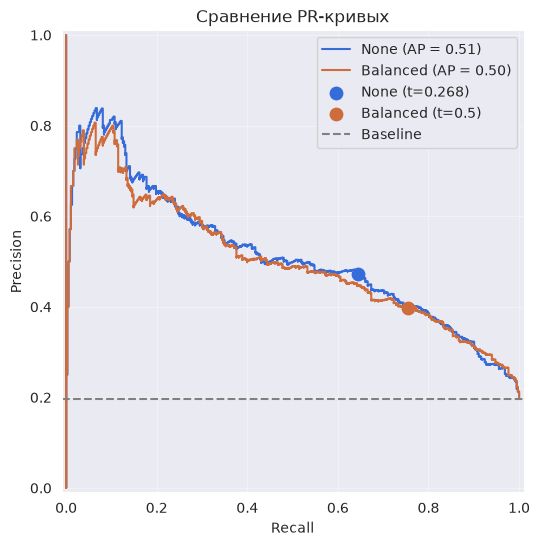

,Precision,Recall,F1,PR-AUC
None (t_F1),0.4732,0.6449,0.5459,0.5121
Balanced (0.5),0.3970,0.7546,0.5203,0.5005


In [204]:
p_none = model_none.predict_proba(X_test)[:, 1]
p_balanced = model_balanced.predict_proba(X_test)[:, 1]

y_pred_none = (p_none >= t_f1).astype(int)
y_pred_balanced = (p_balanced >= 0.5).astype(int)

plt.figure(figsize=(9, 6))
ax = plt.gca()

metrics.PrecisionRecallDisplay.from_predictions(
    y_test, p_none, name='None', ax=ax
)

metrics.PrecisionRecallDisplay.from_predictions(
    y_test, p_balanced, name='Balanced', ax=ax
)

for name, y_pred in [
    ('None (t=0.268)', y_pred_none),
    ('Balanced (t=0.5)', y_pred_balanced)
]:
    precision = metrics.precision_score(y_test, y_pred)
    recall = metrics.recall_score(y_test, y_pred)

    plt.scatter(recall, precision, s=80, zorder=5, label=name)

plt.axhline(y=np.mean(y_test), color='gray', linestyle='--', label='Baseline')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Сравнение PR-кривых')
plt.legend()
plt.grid(True)
plt.show()

display(pd.DataFrame({
    'Precision': [
        metrics.precision_score(y_test, y_pred_none),
        metrics.precision_score(y_test, y_pred_balanced)
    ],
    'Recall': [
        metrics.recall_score(y_test, y_pred_none),
        metrics.recall_score(y_test, y_pred_balanced)
    ],
    'F1': [
        metrics.f1_score(y_test, y_pred_none),
        metrics.f1_score(y_test, y_pred_balanced)
    ],
    'PR-AUC': [
        metrics.average_precision_score(y_test, p_none),
        metrics.average_precision_score(y_test, p_balanced)
    ]
}, index=['None (t_F1)', 'Balanced (0.5)']).round(4))

#### Выводы
PR кривые сильно похожи. Да, можно, т. к. взвешивание классов часто действует аналогично снижению порога классификации и модель чаще предсказывает класс 1, увеличивая Recall и снижая Precision.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [205]:
def evaluate_threshold(model, threshold=0.5):
    p = model.predict_proba(X_test)[:, 1]
    y_pred = (p >= threshold).astype(int)

    return {
        'Accuracy': metrics.accuracy_score(y_test, y_pred),
        'Precision': metrics.precision_score(y_test, y_pred, zero_division=0),
        'Recall': metrics.recall_score(y_test, y_pred),
        'F1': metrics.f1_score(y_test, y_pred),
        'ROC-AUC': metrics.roc_auc_score(y_test, p),
        'PR-AUC': metrics.average_precision_score(y_test, p)
    }

results_final = results_32.copy()

results_final.loc['None (t_F1)'] = evaluate_threshold(model_none, t_f1)
results_final.loc['None (t_R)'] = evaluate_threshold(model_none, t_r)

display(results_final.sort_values('F1', ascending=False))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
None (t_F1),0.789231,0.473180,0.644909,0.545856,0.813537,0.512115
None (t_R),0.765128,0.436975,0.678851,0.531697,0.813537,0.512115
RandomUnderSampler,0.729744,0.401099,0.762402,0.525653,0.809354,0.500791
RandomOverSampler,0.726667,0.397260,0.757180,0.521114,0.811484,0.500225
SMOTE,0.729231,0.399166,0.749347,0.520871,0.812465,0.503985
Balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
NearMiss,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
None,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115


#### Выводы
В нашем сценарии лучшую модель надо выбирать по F1 (почему, объясняли ранее) и, судя по метрикам, лучшей является модель без балансирования с порогом t_F1 = 0.268.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [206]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = model_none
final_threshold = t_f1

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)

## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷